In [1]:
# relevant import

In [2]:
import importlib
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)


<module 'Optimization' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\Optimization.py'>

In [3]:
import matplotlib.pyplot as plt
import torch
import numpy as np

In [4]:
mu_list = [np.array([-5, 4]),
           np.array([5, -4]),
           # np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
           ]

point_l = [[int(p[1]), int(p[0])] for p in mu_list]

mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[0.5,0.25],[0.12,0.2]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# Generate samples
device = 'cpu'  # Change to 'cuda' if using a GPU
# X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )


mog_means = [
    torch.tensor([5.0], dtype=torch.float64),
    # torch.tensor([-5.0], dtype=torch.float64),

]
mog_variances = [torch.tensor([.25], dtype=torch.float64),
     # torch.tensor([.25], dtype=torch.float64),
     ]
weights = torch.tensor([1.,
                        # .5
                        ], dtype=torch.float64)


In [5]:
X = dist_utils.generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

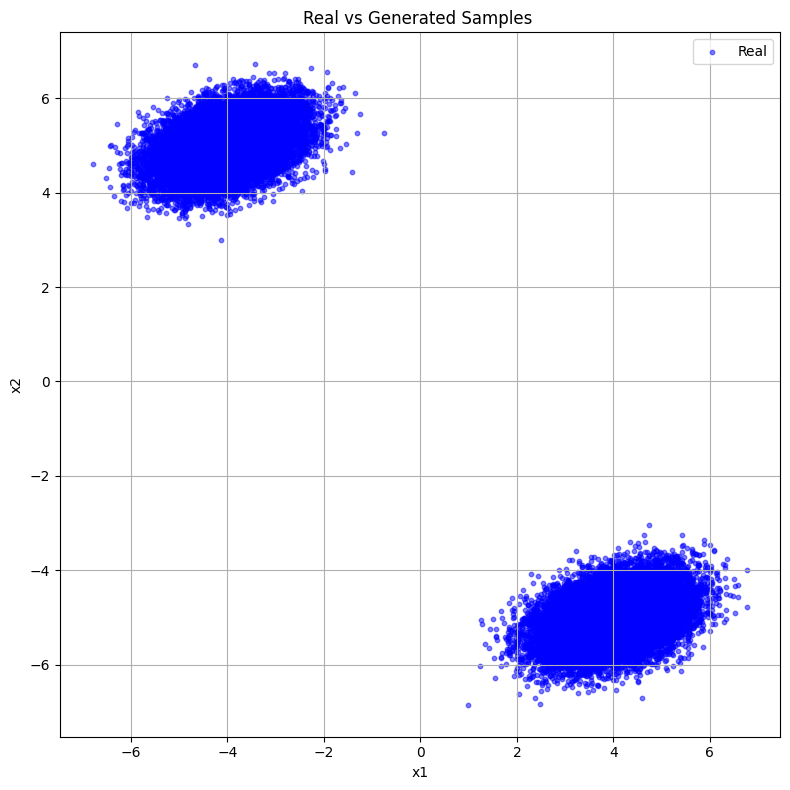

In [6]:
plt.figure(figsize=(8, 8))
plt.scatter(X[:, 0], X[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# better version
# init a model, train
nfeatures= X.shape[1]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=1)
losses = model_cond.train_model(X, nepochs=50, batch_size=3*2048,condition_on=1)

loss: 0.082709: 100%|██████████| 50/50 [01:26<00:00,  1.73s/it]


In [8]:
# init a model, train
X_for_cond_only=X[:,:model_cond.condition_on]
nfeatures= X_for_cond_only.shape[1]
model_uncond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=False,)
losses = model_uncond.train_model(X_for_cond_only, nepochs=50, batch_size=3*2048,condition_on=1)

loss: 0.337230: 100%|██████████| 50/50 [01:12<00:00,  1.45s/it]


In [9]:
x_optim = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD")
# L2_dist= L2_Distance.l2_distance(mu_list, Sigma_list,alpha, mog_means,mog_variances, weights ,x_optim)

Step 1 | x_t: -4.137: 100%|██████████| 99/99 [06:13<00:00,  3.77s/it] 
